# DLENT-RT — Pareto frontier over the objective weights λ (offline)

Kash: *"run a reasonable grid of λ values and give a Pareto frontier"*. Offline analysis only: nothing here enters
the online loop; Phase 0, the reward, s_C and the configs are unchanged.

**Objectives per job** (`dlent_rt.pareto.job_components`, from `dlent_rt.reward`): customer value CV = q·v,
profit PR = φ_job − C_elec, carbon cost CO = s_C·K (minimised, s_C frozen in Phase 0); reward
R(λ) = λ1·CV + λ2·PR − λ3·CO, today λ = (1, 1, 1). The components are computed once and combined linearly for every λ.

**Grid**: λ = 3·w with w on the simplex at step 1/4 (15 points, corners (3,0,0), (0,3,0), (0,0,3) included) plus the
centre (1, 1, 1) (today's reward, not on the 1/4 grid) = 16 points. **7-point subset**: corners, centre, edge
midpoints (1.5, 1.5, 0), (1.5, 0, 1.5), (0, 1.5, 1.5).

**Models** (instance of notebook 03: committed `configs/default.yaml`, seed 42, no drop filter):
fluid LP OPT (weighted sum) and the Chebyshev epigraph LP on the fluid problem, G2 job greedy and the job-level MILP
on all 16 points; StaticPolicy (Phase 0) and DLENT-RT theory on the 7-point subset, with Phase 0 rebuilt for each λ.

This notebook only READS the cache written by `scripts/pareto_run.py` (`reports/week30/pareto/*.csv`); run that
script first. Build: `python notebooks/src/build.py 04_pareto_lambda --execute`.

In [1]:
import subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
sys.path.insert(0, str(ROOT))
from dlent_rt import pareto

PDIR = ROOT / "reports" / "week30" / "pareto"
FIGS = PDIR / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
for f in ("results.csv", "hypervolume.csv", "lambda_invariance_checks.csv", "meta.csv"):
    if not (PDIR / f).is_file():
        raise FileNotFoundError(f"{PDIR / f} missing: run `dlent_venv/bin/python scripts/pareto_run.py` first")
RES = pd.read_csv(PDIR / "results.csv")
HV = pd.read_csv(PDIR / "hypervolume.csv")
CHK = pd.read_csv(PDIR / "lambda_invariance_checks.csv")
META = pd.read_csv(PDIR / "meta.csv", index_col=0)["value"]
NB_COMMIT = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
print(f"NB04 RUN MARKER  notebook built at commit {NB_COMMIT}; results cached at commit {META['commit']}")
print(f"config: {META['config']}  seed {META['seed']}  |stream| = {int(float(META['n_stream'])):,}  "
      f"T = {int(float(META['T'])):,}  s_C = {float(META['s_C']):.4f} $/kgCO2")
RES["lambda"] = [f"({a:g}, {b:g}, {c:g})" for a, b, c in zip(RES.l1, RES.l2, RES.l3)]
MODELS = ["job-level MILP", "fluid LP OPT", "Chebyshev fluid LP", "G2 job greedy", "StaticPolicy (Phase 0)",
          "DLENT-RT theory"]
STYLE = {"job-level MILP": ("black", "o"), "fluid LP OPT": ("dimgray", "s"), "Chebyshev fluid LP": ("teal", "^"),
         "G2 job greedy": ("steelblue", "D"), "StaticPolicy (Phase 0)": ("darkorange", "v"),
         "DLENT-RT theory": ("crimson", "P")}


def savefig(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")

NB04 RUN MARKER  notebook built at commit c2ad514c9d89230d7aef1203abbd467c4d3914b4; results cached at commit c2ad514c9d89230d7aef1203abbd467c4d3914b4
config: git show HEAD:configs/default.yaml  seed 42  |stream| = 15,308  T = 1,432,910  s_C = 228.1843 $/kgCO2


## 1. λ-invariance of Phase 0 (checked before the subset runs)

Phase 0 is rebuilt with each λ of the subset through `run_phase0`. s_C (quantile_linear on λ-free CV and |PR|),
the valuation grid, the hardware profiles and the per-job components must not change with λ; only r̃, τ and λ* do.

In [2]:
display(CHK)
assert CHK[["s_C same as (1,1,1)", "grid edges same", "hardware profiles same", "job components same"]].all().all()

,l1,l2,l3,s_C,"s_C same as (1,1,1)",grid edges same,hardware profiles same,job components same,tau_0,DLENT end reasons
0,3.0,0.0,0.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 2, 'test2': 0, 'test3': 2, 'timeout'..."
1,0.0,3.0,0.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 1, 'test2': 0, 'test3': 0, 'timeout'..."
2,0.0,0.0,3.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 0, 'test2': 0, 'test3': 0, 'timeout'..."
3,1.0,1.0,1.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 0, 'test2': 1, 'test3': 0, 'timeout'..."
4,1.5,1.5,0.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 2, 'test2': 0, 'test3': 1, 'timeout'..."
5,1.5,0.0,1.5,228.184283,True,True,True,True,[0. 0.],"{'test1': 0, 'test2': 0, 'test3': 0, 'timeout'..."
6,0.0,1.5,1.5,228.184283,True,True,True,True,[0. 0.],"{'test1': 0, 'test2': 1, 'test3': 0, 'timeout'..."


## 2. Results: one row per (model, λ)

Σ CV, Σ PR, Σ CO in $ over the stream (fluid rows: per tick × T; "n admitted" for the fluid rows is the expected number
of admissions Σ p x · T). "scalarised" = λ1·ΣCV + λ2·ΣPR − λ3·ΣCO; for the Chebyshev rows `chebyshev_t` is the
epigraph value. `nondominated` = non-dominated among the same model's points (CV, PR maximised, CO minimised).

In [3]:
cols = ["model", "lambda", "sum_CV", "sum_PR", "sum_CO", "scalarised", "n_admitted", "nondominated", "runtime_s"]
for m in MODELS:
    g = RES[RES.model == m][cols + [c for c in ("status", "gap", "chebyshev_t", "phys_rejects") if c in RES]]
    print(f"\n=== {m} ({len(g)} points)")
    display(g.drop(columns="model").set_index("lambda").style.format(precision=2))


=== job-level MILP (16 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,phys_rejects
lambda,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.00,no job with R > 0,0.00,nan,nan
"(0, 0.75, 2.25)",69462.97,29662.11,3180.09,15091.38,8035.00,True,0.11,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0, 1.5, 1.5)",101837.31,39989.68,9313.43,46014.38,10106.00,True,0.17,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0, 2.25, 0.75)",121077.03,46941.00,22139.20,89012.85,11424.00,True,0.34,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0, 3, 0)",135748.28,52579.68,58351.31,157739.05,12287.00,True,1.89,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0.75, 0, 2.25)",115068.62,24222.56,9721.80,64427.42,11703.00,True,0.14,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0.75, 0.75, 1.5)",124752.66,41554.72,15446.05,101561.46,12009.00,True,0.19,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0.75, 1.5, 0.75)",137233.23,47936.12,30992.33,151584.85,12708.00,True,0.27,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan
"(0.75, 2.25, 0)",143389.65,51751.44,60508.32,223982.97,13138.00,True,1.92,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan



=== fluid LP OPT (16 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,phys_rejects
lambda,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.01,Optimal,nan,nan,nan
"(0, 0.75, 2.25)",62204.45,24855.31,2795.64,12351.30,6588.00,True,0.02,Optimal,nan,nan,nan
"(0, 1.5, 1.5)",95783.48,35227.67,8933.26,39441.61,8739.00,True,0.01,Optimal,nan,nan,nan
"(0, 2.25, 0.75)",114686.42,41551.91,20785.22,77902.88,10104.00,True,0.02,Optimal,nan,nan,nan
"(0, 3, 0)",136621.75,48858.85,78491.68,146576.56,11609.00,True,0.03,Optimal,nan,nan,nan
"(0.75, 0, 2.25)",114679.99,22993.37,9693.23,64200.21,11572.00,True,0.01,Optimal,nan,nan,nan
"(0.75, 0.75, 1.5)",124918.97,35462.26,15425.61,97147.51,11765.00,True,0.01,Optimal,nan,nan,nan
"(0.75, 1.5, 0.75)",137304.36,42161.62,31194.61,142824.74,12350.00,True,0.01,Optimal,nan,nan,nan
"(0.75, 2.25, 0)",148759.25,47386.28,85343.80,218188.58,13269.00,True,0.02,Optimal,nan,nan,nan



=== Chebyshev fluid LP (16 points)


...

,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,phys_rejects
lambda,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.18,nan,nan,nan,0.00
"(0, 0.75, 2.25)",69462.97,29662.11,3180.09,15091.38,8035.00,True,0.27,nan,nan,nan,0.00
"(0, 1.5, 1.5)",101837.31,39989.68,9313.43,46014.38,10106.00,True,0.29,nan,nan,nan,0.00
"(0, 2.25, 0.75)",120448.73,46843.13,22061.04,88851.26,11417.00,True,0.41,nan,nan,nan,13.00
"(0, 3, 0)",132428.66,50960.23,56512.19,152880.70,12291.00,True,0.44,nan,nan,nan,401.00
"(0.75, 0, 2.25)",115068.62,24222.56,9721.80,64427.42,11703.00,True,0.24,nan,nan,nan,0.00
"(0.75, 0.75, 1.5)",124752.66,41554.72,15446.05,101561.46,12009.00,True,0.24,nan,nan,nan,1.00
"(0.75, 1.5, 0.75)",136570.00,47829.40,31122.74,150829.54,12688.00,True,0.24,nan,nan,nan,48.00
"(0.75, 2.25, 0)",137278.88,49659.89,58385.09,214693.91,13126.00,True,0.29,nan,nan,nan,493.00



=== StaticPolicy (Phase 0) (7 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,phys_rejects
lambda,,,,,,,,,,,
"(3, 0, 0)",63469.01,13087.78,45740.90,190407.02,12200.00,True,0.30,nan,nan,nan,346.00
"(0, 3, 0)",56967.63,13284.87,41967.31,39854.61,10253.00,True,0.28,nan,nan,nan,240.00
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.21,nan,nan,nan,0.00
"(1, 1, 1)",54375.81,11243.11,11402.52,54216.40,10226.00,True,0.27,nan,nan,nan,1.00
"(1.5, 1.5, 0)",61153.73,13348.10,44212.85,111752.75,11444.00,True,0.30,nan,nan,nan,309.00
"(1.5, 0, 1.5)",54214.41,10325.99,8661.91,68328.76,10652.00,True,0.29,nan,nan,nan,1.00
"(0, 1.5, 1.5)",43199.66,9954.11,5022.13,7397.97,8295.00,True,0.28,nan,nan,nan,0.00



=== DLENT-RT theory (7 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,phys_rejects
lambda,,,,,,,,,,,
"(3, 0, 0)",57944.45,10096.22,34037.57,173833.35,9181.00,True,467.09,nan,nan,nan,135.00
"(0, 3, 0)",50103.78,11359.88,30707.65,34079.63,7239.00,True,486.30,nan,nan,nan,96.00
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,208.85,nan,nan,nan,0.00
"(1, 1, 1)",50288.44,9116.34,11013.17,48391.61,7405.00,True,428.76,nan,nan,nan,2.00
"(1.5, 1.5, 0)",55995.20,10153.49,33217.29,99223.03,8388.00,True,480.77,nan,nan,nan,125.00
"(1.5, 0, 1.5)",48220.09,8231.42,8600.04,59430.07,7851.00,True,541.49,nan,nan,nan,3.00
"(0, 1.5, 1.5)",40708.02,8775.80,6193.29,3873.76,5771.00,True,362.65,nan,nan,nan,0.00


## 3. Corners and degenerate cases

* λ = (3, 0, 0): R = 3·CV = 3·q·v > 0 for every job. The job-level models (MILP, G2) want every job and are limited
  by the per-tick capacity only; the fluid LP admits every type (its average capacity is slack); StaticPolicy and
  DLENT-RT admit every type seen in H (types unseen in H have r̃ = 0) up to the physical gate (and thinning).
* λ = (0, 3, 0): R = 3·PR, admit the jobs with φ_job > C_elec (the profitable ones), carbon ignored.
* λ = (0, 0, 3): R = −3·CO ≤ 0 for every job: **admit nothing** for every model (a job with K = 0 has R = 0, not
  > 0). The frontier point is (0, 0, 0): degenerate.

In [4]:
corner = RES[[any(np.allclose((a, b, c), k) for k in pareto.CORNERS) for a, b, c in zip(RES.l1, RES.l2, RES.l3)]]
def label(r):
    if r.n_admitted == 0:
        return "admit nothing (degenerate: R <= 0 for every job)"
    if r.l1 > 0:                                           # CV corner: R = 3 q v > 0 for every job
        if r.model == "fluid LP OPT" or r.model == "Chebyshev fluid LP":
            return "every type admitted (x = 1): the average-occupancy capacity is slack"
        if r.model in ("StaticPolicy (Phase 0)", "DLENT-RT theory"):
            return ("every type SEEN in H has r~ > 0 (unseen types have r~ = 0 and stay rejected); "
                    "then the physical gate" + (" and thinning" if r.model.startswith("DLENT") else ""))
        return "every job has R > 0: admit-all up to the per-tick capacity"
    return "admit the profitable jobs / types (PR > 0), carbon ignored"
corner = corner.assign(corner_solution=corner.apply(label, axis=1))
display(corner[["model", "lambda", "n_admitted", "sum_CV", "sum_PR", "sum_CO", "corner_solution"]]
        .set_index(["lambda", "model"]).sort_index().style.format(precision=2))

## 4. Frontier projections

Two-dimensional projections of the three-objective points (CO on the x axis, minimised). Filled markers =
non-dominated within the model; the centre λ = (1, 1, 1) is circled.

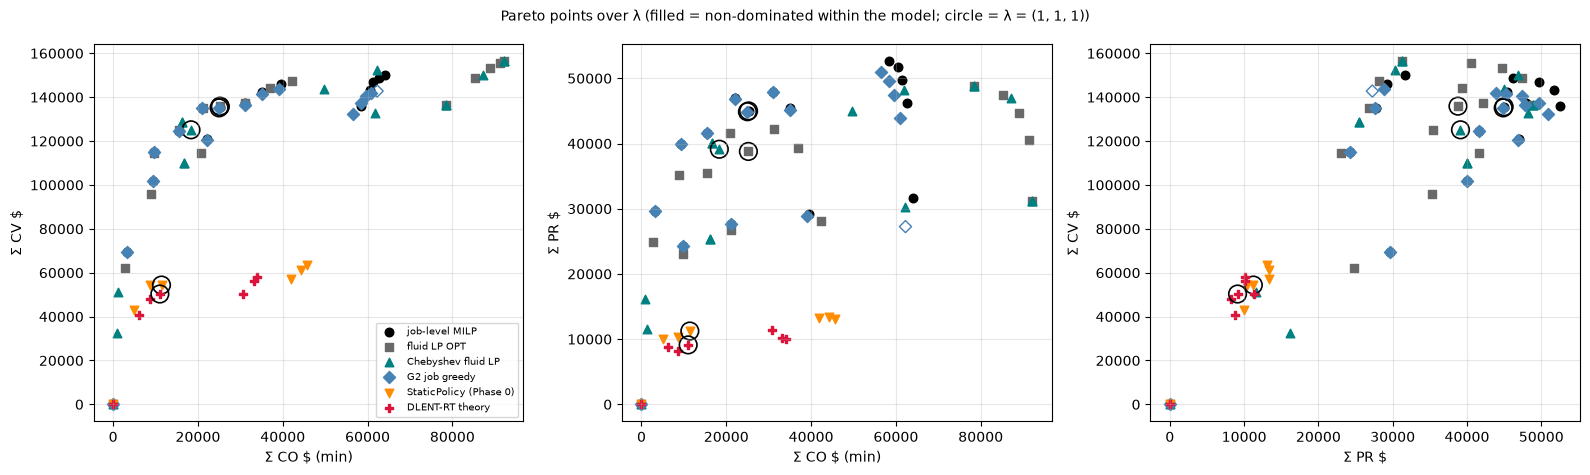

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
pairs = [("sum_CO", "sum_CV", "Σ CO $ (min)", "Σ CV $"), ("sum_CO", "sum_PR", "Σ CO $ (min)", "Σ PR $"),
         ("sum_PR", "sum_CV", "Σ PR $", "Σ CV $")]
for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    for m in MODELS:
        g = RES[RES.model == m]
        col, mk = STYLE[m]
        nd = g.nondominated.astype(bool)
        ax.scatter(g.loc[nd, xc], g.loc[nd, yc], color=col, marker=mk, s=38, label=m)
        ax.scatter(g.loc[~nd, xc], g.loc[~nd, yc], facecolors="none", edgecolors=col, marker=mk, s=38)
        cen = g[(g.l1 == 1) & (g.l2 == 1) & (g.l3 == 1)]
        ax.scatter(cen[xc], cen[yc], facecolors="none", edgecolors="k", s=160, lw=1.2)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
fig.suptitle("Pareto points over λ (filled = non-dominated within the model; circle = λ = (1, 1, 1))", fontsize=10)
plt.tight_layout(); savefig(fig, "pareto_projections"); plt.show()

## 5. The weight simplex: Σ CV, Σ PR, Σ CO of the job-level MILP and of DLENT-RT per λ

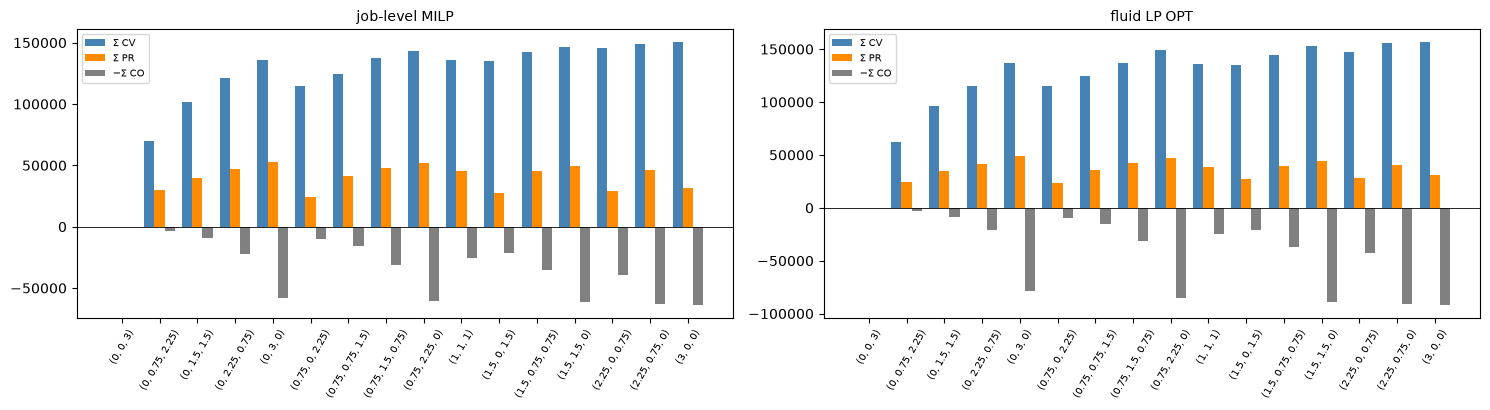

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=False)
for ax, m in zip(axes, ["job-level MILP", "fluid LP OPT"]):
    g = RES[RES.model == m].sort_values(["l1", "l2"])
    x = np.arange(len(g))
    ax.bar(x - 0.27, g.sum_CV, 0.27, color="steelblue", label="Σ CV")
    ax.bar(x, g.sum_PR, 0.27, color="darkorange", label="Σ PR")
    ax.bar(x + 0.27, -g.sum_CO, 0.27, color="gray", label="−Σ CO")
    ax.set_xticks(x, g["lambda"], rotation=60, fontsize=7); ax.axhline(0, color="k", lw=0.6)
    ax.set_title(m, fontsize=10); ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, "objectives_per_lambda"); plt.show()

## 6. Hypervolume

Exact 3-D hypervolume (`pareto.hypervolume_3d`) of each model's points, objectives (CV, PR, −CO) maximised, with a
COMMON reference point for every model: the componentwise worst value over all rows of all models, pushed out by
1% of the range (so boundary points still count). "7-point subset" makes the six models comparable on the same λ.

In [7]:
print("reference point (CV, PR, -CO) $:", META["hypervolume reference point (CV, PR, -CO) $"])
display(HV.pivot(index="model", columns="points", values="hypervolume").loc[MODELS].style.format("{:.4e}"))

reference point (CV, PR, -CO) $: [-1562.6459817747236, -525.7968424060596, -93043.21238305612]


points,7-point subset,all its grid points
model,,
job-level MILP,5.5116e+14,6.0138e+14
fluid LP OPT,4.5136e+14,5.2094e+14
Chebyshev fluid LP,4.2675e+14,4.9618e+14
G2 job greedy,5.3231e+14,5.8040e+14
StaticPolicy (Phase 0),6.9287e+13,6.9287e+13
DLENT-RT theory,5.5175e+13,5.5175e+13


## 7. Weighted sum vs Chebyshev on the fluid problem

The fluid problem is an LP, so its set of objective vectors is convex and every Pareto point is supported: the
weighted sum and the Chebyshev epigraph LP trace the same front (they can pick different points for the same
weights). Chebyshev reaches unsupported points only on a non-convex front, e.g. a discrete one (see
`tests/test_pareto.py`). Ideal / nadir of the Chebyshev LP = single-objective fluid optima / payoff-table nadir.

**Caution, orientation of the weights.** In the requested form max t s.t. t ≤ w_k·(f_k − nadir_k)/(ideal_k − nadir_k),
a LARGER w_k makes objective k's constraint LOOSER, i.e. objective k matters LESS (the opposite of the weighted sum,
where a larger λ_k matters more): e.g. λ = (0, 0.75, 2.25) gives far more carbon under Chebyshev than under the weighted
sum. The LP is also degenerate: the optimum t is set by the smallest positive weight, and many x reach it, so the
reported point is one arbitrary LP vertex among ties. The usual form (t ≤ (f_k − nadir_k)/(w_k·range_k), or min–max of
w_k·(ideal_k − f_k)/range_k) restores "larger weight = more important"; it is not run here.

In [8]:
print("fluid ideal (CV, PR, -CO) per tick:", META["fluid ideal (CV, PR, -CO) per tick"])
print("fluid nadir (CV, PR, -CO) per tick:", META["fluid nadir (CV, PR, -CO) per tick"])
ws = RES[RES.model == "fluid LP OPT"].set_index("lambda")[["sum_CV", "sum_PR", "sum_CO"]]
ch = RES[RES.model == "Chebyshev fluid LP"].set_index("lambda")[["sum_CV", "sum_PR", "sum_CO", "chebyshev_t"]]
display(ws.join(ch, lsuffix=" (weighted sum)", rsuffix=" (Chebyshev)").style.format(precision=2))

fluid ideal (CV, PR, -CO) per tick: [0.10905402166044786, 0.03409764352296922, -0.0]
fluid nadir (CV, PR, -CO) per tick: [0.0, 0.0, -0.06429014554889798]


,sum_CV (weighted sum),sum_PR (weighted sum),sum_CO (weighted sum),sum_CV (Chebyshev),sum_PR (Chebyshev),sum_CO (Chebyshev),chebyshev_t
lambda,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,0.00,1.00
"(0, 0.75, 2.25)",62204.45,24855.31,2795.64,132785.78,48207.57,61823.99,0.25
"(0, 1.5, 1.5)",95783.48,35227.67,8933.26,109946.48,40028.54,16649.31,0.41
"(0, 2.25, 0.75)",114686.42,41551.91,20785.22,32423.97,16134.61,857.95,0.25
"(0, 3, 0)",136621.75,48858.85,78491.68,136621.75,48858.85,78491.68,1.00
"(0.75, 0, 2.25)",114679.99,22993.37,9693.23,152215.06,30281.19,62210.43,0.24
"(0.75, 0.75, 1.5)",124918.97,35462.26,15425.61,143911.62,44996.48,49702.19,0.23
"(0.75, 1.5, 0.75)",137304.36,42161.62,31194.61,128672.76,25413.46,16266.10,0.21
"(0.75, 2.25, 0)",148759.25,47386.28,85343.80,156264.60,31255.51,92121.99,0.25


## 8. Runtime

In [9]:
display(RES.groupby("model")["runtime_s"].agg(["count", "sum", "max"]).loc[MODELS].style.format(precision=2))
print(f"total script runtime: {float(META['total runtime s']):,.0f} s")

,count,sum,max
model,,,
job-level MILP,16,15.76,3.63
fluid LP OPT,16,0.29,0.04
Chebyshev fluid LP,16,0.60,0.05
G2 job greedy,16,4.68,0.44
StaticPolicy (Phase 0),7,1.94,0.30
DLENT-RT theory,7,2975.90,541.49


total script runtime: 550 s
